# Credit Scoring: a Regulatory Scorecard vs Machine Learning

**Goal.** Build a probability-of-default (PD) model for loan applicants the way a bank's
credit risk team would, then ask the question every model validation committee asks:
*is a machine-learning model worth losing the interpretability of a scorecard?*

| Step | Method |
|---|---|
| Feature engineering | Weight of Evidence (WoE) binning, Information Value (IV) |
| Model 1 | Logistic regression on WoE, turned into a points scorecard |
| Model 2 | Gradient boosting (scikit-learn `HistGradientBoostingClassifier`) |
| Validation | Gini, KS, ROC, calibration, rating master scale, PSI stability |

**Data.** 30,000 synthetic applications with income, employment, debt-to-income (DTI),
card utilisation, late payments, credit history and loan amount. The hidden default
mechanism includes non-linear effects and an interaction, so the ML model has something to find.

In [1]:
import os, sys, subprocess
if "google.colab" in sys.modules and not os.path.exists("scoring.py"):
    subprocess.run(["git", "clone", "-q", "https://github.com/adamrejeb86-del/-finance-portfolio.git"], check=True)
    os.chdir("-finance-portfolio/13-credit-scoring-ml")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_curve
from scoring import (generate_applications, WoEEncoder, scorecard_points, score_from_pd, gini, ks_statistic,
                     calibration_table, population_stability_index, assign_grade, MASTER_SCALE)

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
NAVY, BORDEAUX, GREY, TEAL = "#1f3b5c", "#7a1f2b", "#8a8a8a", "#2a7f7f"
df = generate_applications(30_000, seed=0)
print(f"{len(df):,} applications, default rate {df['default'].mean():.2%}, income missing for {df['income'].isna().mean():.1%}")
df.describe(include="all").T[["count", "mean", "min", "max", "unique", "top"]].round(2)

30,000 applications, default rate 5.89%, income missing for 6.0%


,count,mean,min,max,unique,top
age,30000.0,44.966533,21.0,69.0,NaN,NaN
income,28214.0,42015.222939,5000.0,238700.0,NaN,NaN
employment,30000,NaN,NaN,NaN,4,permanent
home,30000,NaN,NaN,NaN,3,mortgage
history_years,30000.0,23.195537,0.0,51.0,NaN,NaN
loan_amount,30000.0,14355.363333,1000.0,80000.0,NaN,NaN
dti,30000.0,0.301397,0.012,1.025,NaN,NaN
utilisation,30000.0,0.425163,0.003,1.0,NaN,NaN
late_payments,30000.0,0.590267,0.0,7.0,NaN,NaN
default,30000.0,0.058867,0.0,1.0,NaN,NaN


## 1. Exploring the risk drivers

Default rates by bucket show the shape of each relationship. Utilisation and age are
**non-linear**: very low and very high utilisation are both riskier than moderate use,
and the youngest and oldest applicants default more.

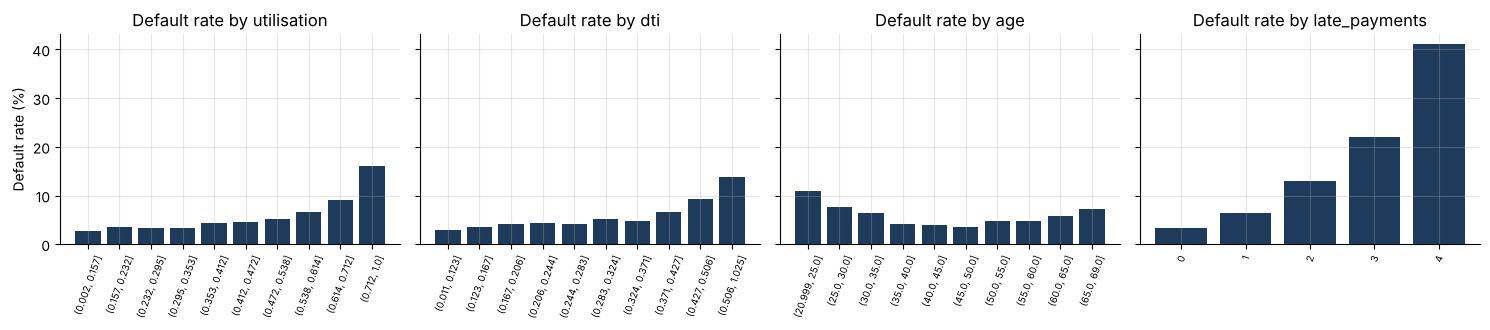

In [2]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True)
for ax, col, q in zip(axes, ["utilisation", "dti", "age", "late_payments"], [10, 10, 10, None]):
    b = pd.qcut(df[col], q, duplicates="drop") if q else df[col].clip(upper=4)
    rates = df.groupby(b, observed=True)["default"].mean()
    ax.bar(range(len(rates)), rates.values * 100, color=NAVY)
    ax.set_xticks(range(len(rates)), [str(i) for i in rates.index], rotation=70, fontsize=7)
    ax.set_title(f"Default rate by {col}")
axes[0].set_ylabel("Default rate (%)")
plt.tight_layout(); plt.savefig("images/risk_drivers.png", dpi=150); plt.show()

## 2. Weight of Evidence and Information Value

Each variable is cut into bins (quantiles, plus a bin for missing values) and each bin is
replaced by its **Weight of Evidence**: $\text{WoE} = \ln\frac{\%\,\text{non-defaulters}}{\%\,\text{defaulters}}$.
WoE turns every variable, linear or not, numeric or categorical, into a monotone risk
score, and handles missing data naturally. **Information Value** ranks predictive power.

In [3]:
X, y = df.drop(columns="default"), df["default"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)
enc = WoEEncoder(n_bins=6).fit(X_train, y_train)
iv = enc.information_values()
strength = pd.cut(iv, [-1, 0.02, 0.1, 0.3, 10], labels=["useless", "weak", "medium", "strong"])
pd.DataFrame({"Information value": iv.round(3), "Predictive power": strength})

,Information value,Predictive power
late_payments,0.499,strong
utilisation,0.323,strong
dti,0.271,medium
history_years,0.121,medium
age,0.116,medium
employment,0.093,weak
income,0.045,weak
loan_amount,0.013,useless
home,0.001,useless


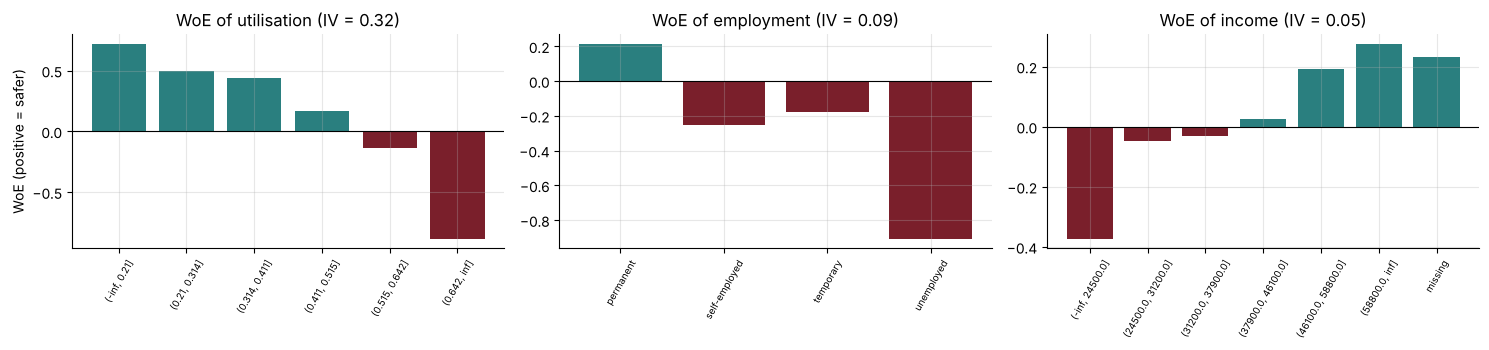

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, col in zip(axes, ["utilisation", "employment", "income"]):
    t = enc.tables[col]
    ax.bar(range(len(t)), t["woe"], color=[TEAL if w > 0 else BORDEAUX for w in t["woe"]])
    ax.set_xticks(range(len(t)), t.index, rotation=60, fontsize=7); ax.axhline(0, color="black", lw=0.8)
    ax.set_title(f"WoE of {col} (IV = {iv[col]:.2f})")
axes[0].set_ylabel("WoE (positive = safer)")
plt.tight_layout(); plt.savefig("images/woe.png", dpi=150); plt.show()

Variables with an IV below 0.02 (here `home`) would normally be dropped. We keep the full
set to stay comparable with the ML model. Note how the **missing income** bin carries its own risk.

## 3. Model 1: logistic scorecard

A logistic regression on the WoE values, then converted to **points** (600 points at
50:1 good:bad odds, 20 points to double the odds). Credit officers read the points table
directly: every decision can be explained bin by bin.

In [5]:
W_train, W_test = enc.transform(X_train), enc.transform(X_test)
logit = LogisticRegression(max_iter=2000).fit(W_train, y_train)
p_lr = logit.predict_proba(W_test)[:, 1]
coefs = dict(zip(W_train.columns, logit.coef_[0]))
points = scorecard_points(coefs, logit.intercept_[0], enc)
display(pd.Series(coefs).round(3).to_frame("Coefficient on WoE").T)
points[points["feature"].isin(["late_payments", "employment"])].round(1)

,age,income,employment,home,history_years,loan_amount,dti,utilisation,late_payments
Coefficient on WoE,-0.581,-0.897,-1.047,-0.149,-0.639,-0.543,-0.779,-0.506,-0.838


,feature,bin,woe,points
13,employment,permanent,0.2,69.4
14,employment,self-employed,-0.3,55.3
15,employment,temporary,-0.2,57.5
16,employment,unemployed,-0.9,35.6
44,late_payments,"(-inf, 0.5]",0.6,77.3
45,late_payments,"(0.5, 1.5]",-0.1,61.7
46,late_payments,"(1.5, 2.5]",-0.9,41.0
47,late_payments,"(2.5, 3.5]",-1.5,26.3
48,late_payments,"(3.5, 4.5]",-2.2,9.4
49,late_payments,"(4.5, inf]",-3.3,-17.6


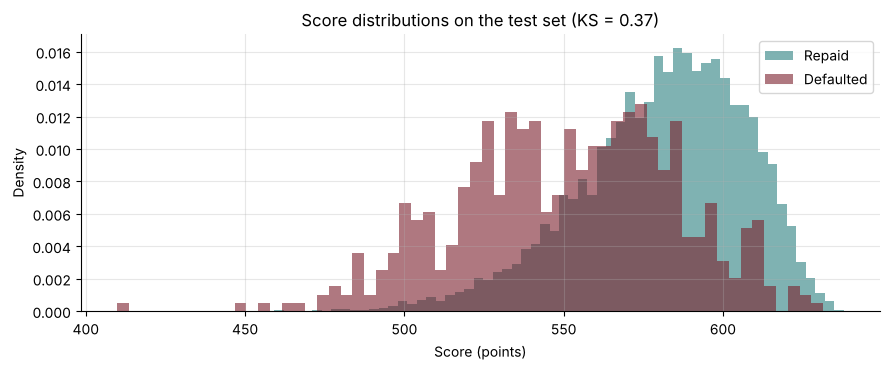

In [6]:
score = score_from_pd(p_lr)
plt.figure(figsize=(9, 3.8))
plt.hist(score[y_test == 0], bins=60, density=True, alpha=0.6, color=TEAL, label="Repaid")
plt.hist(score[y_test == 1], bins=60, density=True, alpha=0.6, color=BORDEAUX, label="Defaulted")
plt.xlabel("Score (points)"); plt.ylabel("Density"); plt.legend()
plt.title(f"Score distributions on the test set (KS = {ks_statistic(y_test, p_lr):.2f})")
plt.tight_layout(); plt.savefig("images/score_distribution.png", dpi=150); plt.show()

## 4. Model 2: gradient boosting

Trees find the non-linearities and the interaction by themselves, from raw values (with
categorical variables one-hot encoded, missing values handled natively).

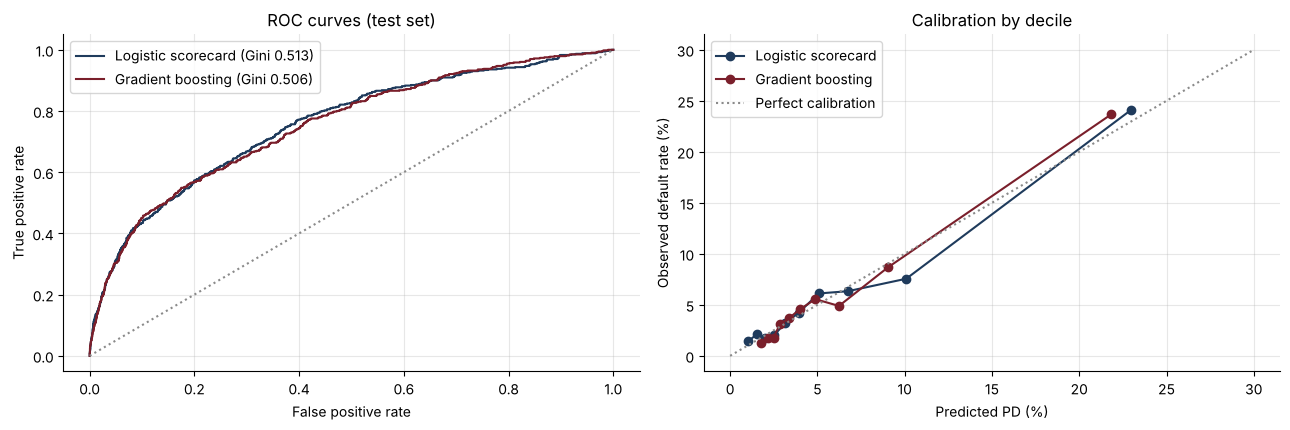

,Gini,KS,Mean PD,Observed DR
Logistic scorecard,0.5126,0.3738,0.0591,0.0589
Gradient boosting,0.5061,0.3743,0.0586,0.0589


In [7]:
Xd = pd.get_dummies(X, columns=["employment", "home"], dtype=float)
gb = HistGradientBoostingClassifier(max_iter=400, learning_rate=0.04, max_leaf_nodes=15, l2_regularization=1.0,
                                    early_stopping=True, validation_fraction=0.15, random_state=0)
gb.fit(Xd.loc[X_train.index], y_train)
p_gb = gb.predict_proba(Xd.loc[X_test.index])[:, 1]

results = pd.DataFrame({"Gini": [gini(y_test, p_lr), gini(y_test, p_gb)], "KS": [ks_statistic(y_test, p_lr), ks_statistic(y_test, p_gb)],
                        "Mean PD": [p_lr.mean(), p_gb.mean()], "Observed DR": [y_test.mean()] * 2},
                       index=["Logistic scorecard", "Gradient boosting"])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for p, name, c in [(p_lr, "Logistic scorecard", NAVY), (p_gb, "Gradient boosting", BORDEAUX)]:
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=c, label=f"{name} (Gini {gini(y_test, p):.3f})")
    cal = calibration_table(y_test, p)
    axes[1].plot(cal["predicted_pd"] * 100, cal["observed_dr"] * 100, "o-", color=c, label=name)
axes[0].plot([0, 1], [0, 1], color=GREY, ls=":"); axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curves (test set)")
mx = 30
axes[1].plot([0, mx], [0, mx], color=GREY, ls=":", label="Perfect calibration")
axes[1].set(xlabel="Predicted PD (%)", ylabel="Observed default rate (%)", title="Calibration by decile")
for ax in axes: ax.legend()
plt.tight_layout(); plt.savefig("images/roc_calibration.png", dpi=150); plt.show()
results.round(4)

**Reading the results.** Once the variables are binned with care, the scorecard matches
gradient boosting (a Gini of about 0.51 for both): the WoE bins already capture the
non-linear effects. On tabular credit data the ML uplift is often small, so for a
regulatory (IRB) model the scorecard's transparency wins. ML remains useful as a
**challenger model** that flags what the scorecard misses.

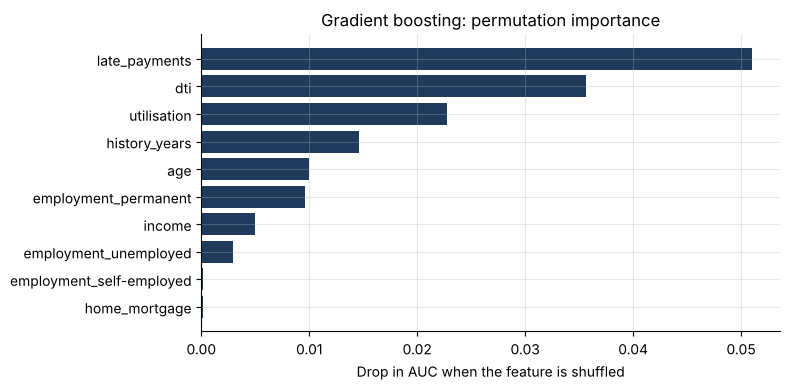

In [8]:
imp = permutation_importance(gb, Xd.loc[X_test.index], y_test, scoring="roc_auc", n_repeats=5, random_state=0)
importance = pd.Series(imp.importances_mean, index=Xd.columns).sort_values(ascending=True).tail(10)
plt.figure(figsize=(8, 4))
plt.barh(importance.index, importance.values, color=NAVY)
plt.xlabel("Drop in AUC when the feature is shuffled"); plt.title("Gradient boosting: permutation importance")
plt.tight_layout(); plt.savefig("images/importance.png", dpi=150); plt.show()

## 5. Rating master scale

Banks do not use raw PDs for decisions: they map them to a **master scale** of rating
grades, each with a PD range. Observed default rates should increase grade by grade.

In [9]:
grades = pd.DataFrame({"grade": assign_grade(p_lr), "pd": p_lr, "default": y_test.values})
scale = grades.groupby("grade").agg(Applicants=("pd", "size"), Mean_PD=("pd", "mean"), Observed_DR=("default", "mean"))
scale["Share"] = scale["Applicants"] / scale["Applicants"].sum()
scale.reindex([g[0] for g in MASTER_SCALE]).dropna().style.format({"Mean_PD": "{:.2%}", "Observed_DR": "{:.2%}", "Share": "{:.1%}", "Applicants": "{:.0f}"})

,Applicants,Mean_PD,Observed_DR,Share
grade,,,,
4 (BB+),1301,1.16%,1.92%,14.5%
5 (BB-),3180,2.40%,2.20%,35.3%
6 (B),2708,5.23%,5.50%,30.1%
7 (B-),1389,12.06%,11.02%,15.4%
8 (CCC),422,31.04%,31.52%,4.7%


## 6. Monitoring: Population Stability Index

A model is only valid for the population it was built on. When the economy turns, new
applicants carry more debt. PSI compares the score distribution of new applicants with the
development sample: above 0.25, the model must be reviewed.

In [10]:
new = generate_applications(10_000, seed=99)
new["dti"] = (new["dti"] * 1.4).clip(upper=1.2)
new["utilisation"] = (new["utilisation"] + 0.15).clip(upper=1)
new["late_payments"] = new["late_payments"] + (np.random.default_rng(5).random(len(new)) < 0.2)
psi_same = population_stability_index(score_from_pd(logit.predict_proba(W_train)[:, 1]), score)
psi_shift = population_stability_index(score_from_pd(logit.predict_proba(W_train)[:, 1]),
                                       score_from_pd(logit.predict_proba(enc.transform(new.drop(columns="default")))[:, 1]))
print(f"PSI, test set vs development sample:          {psi_same:.3f}  (stable)")
print(f"PSI, downturn applicants vs development sample: {psi_shift:.3f}  ({'review the model' if psi_shift > 0.25 else 'monitor'})")

PSI, test set vs development sample:          0.001  (stable)
PSI, downturn applicants vs development sample: 0.305  (review the model)


## Conclusions
- The WoE scorecard reaches a Gini of about 0.51 with a fully explainable points table,
  level with gradient boosting: good binning captures the non-linear effects.
- Both models are calibrated (mean PD = observed default rate) and rank applicants
  monotonically across rating grades.
- PSI detects the population shift of a downturn from the applications alone, before
  any default is observed.
- **Next steps:** reject inference, SHAP explanations for the ML model, an IFRS 9 lifetime
  PD term structure, and fairness checks across customer groups.